# Atelier AI — Fashion Recommendation Analysis

This notebook documents the development and evaluation of a fashion
recommendation system for client advisors.

The task is to recommend 12 distinct products per customer based on
purchase likelihood over the following seven days, using information
available before the prediction cutoff.

The current version establishes the notebook execution environment.
Data exploration and modelling will be added incrementally.

## 1. Environment

The notebook uses the project's Python environment and imports the
`atelier_ai` package installed from the repository's `src` directory.

Dependencies are declared in `pyproject.toml` and resolved in `uv.lock`.

In [1]:
import sys
from pathlib import Path

import pandas as pd

import atelier_ai

print("Python version:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("Package location:", Path(atelier_ai.__file__).resolve())
print("pandas version:", pd.__version__)

Python version: 3.12.14
Python executable: /Users/oumar/Developer/portfolio/atelier-ai-project/.venv/bin/python
Package location: /Users/oumar/Developer/portfolio/atelier-ai-project/src/atelier_ai/__init__.py
pandas version: 3.0.6


## 2. Data Source and Scope

The project uses the H&M Personalized Fashion Recommendations dataset.

The initial scope includes purchase transactions, article metadata and
customer metadata. Images are deferred.

Source documentation and handling decisions are recorded in the
[data card](../docs/data_card.md). Acquired files are identified in the
[data manifest](../docs/data_manifest.json).

## 3. Data Loading

### 3.1. File Locations and Preview Parameters

The initial loading check reads the first 1,000 records from each file.
These previews are not random samples and will not be used to infer
population-level patterns.

File locations are resolved from the project's editable package.

In [2]:
PROJECT_ROOT = Path(atelier_ai.__file__).resolve().parents[2]
RAW_DATA_DIRECTORY = PROJECT_ROOT / "data" / "raw" / "hm"

PREVIEW_ROWS = 1_000

SOURCE_FILENAMES = (
    "articles.csv",
    "customers.csv",
    "transactions_train.csv",
)

for filename in SOURCE_FILENAMES:
    path = RAW_DATA_DIRECTORY / filename
    if not path.is_file():
        raise FileNotFoundError(f"Required source file not found: {path}")

print("Raw data directory found.")

Raw data directory found.


### 3.2. Limited Reads

All fields are initially read as strings to preserve their lexical
representation, including identifiers with leading zeros.

Automatic missing-value recognition is disabled for this inspection.
Empty fields therefore remain empty strings. Numerical, categorical and
date conversions will be defined after inspection.

In [3]:
previews = {}

for filename in SOURCE_FILENAMES:
    dataset_name = Path(filename).stem

    previews[dataset_name] = pd.read_csv(
        RAW_DATA_DIRECTORY / filename,
        nrows=PREVIEW_ROWS,
        dtype="string",
        keep_default_na=False,
        encoding="utf-8",
    )

### 3.3. Loading Summary

The summary reports loaded dimensions and estimated DataFrame memory
usage for each preview. Loaded row counts are not full-file row counts.

Published outputs contain structural diagnostics rather than source
records.

In [4]:
summary_rows = []

for dataset_name, frame in previews.items():
    summary_rows.append(
        {
            "dataset": dataset_name,
            "rows_loaded": len(frame),
            "columns_loaded": frame.shape[1],
            "memory_mib": (
                frame.memory_usage(index=True, deep=True).sum() / 1024**2
            ),
        }
    )

loading_summary = pd.DataFrame(summary_rows)
loading_summary.round({"memory_mib": 3})

,dataset,rows_loaded,columns_loaded,memory_mib
0,articles,1000,25,1.440
1,customers,1000,7,0.464
2,transactions_train,1000,5,0.334


### 3.4. Full-File Reading Strategy

All three files are scanned in chunks of up to 100,000 records.
Chunks are processed sequentially rather than accumulated.

Article and customer fields remain strings pending detailed inspection.

For transactions:
- customer, article and sales-channel identifiers remain strings;
- dates are parsed using the YYYY-MM-DD format;
- prices are converted to nullable Float64 values;
- blank dates and prices are treated as missing;
- invalid non-blank values raise conversion errors.

Source files are not modified. No price rescaling or currency
interpretation is applied.

In [5]:
from time import perf_counter

CHUNK_ROWS = 100_000

### 3.5. Full-File Scan

The scan reports parsed record counts, chunk counts, elapsed time and
the largest observed processed-chunk memory estimate.

Chunk memory is measured after the selected conversions. It is not a
measurement of total process memory or peak memory during parsing.

In [6]:
scan_rows = []
transaction_type_summary = None

for filename in SOURCE_FILENAMES:
    dataset_name = Path(filename).stem
    rows_read = 0
    chunks_read = 0
    max_chunk_mib = 0.0
    started_at = perf_counter()

    print(f"Scanning {filename}...", flush=True)

    with pd.read_csv(
        RAW_DATA_DIRECTORY / filename,
        chunksize=CHUNK_ROWS,
        dtype="string",
        keep_default_na=False,
        encoding="utf-8",
    ) as reader:
        for chunk in reader:
            if dataset_name == "transactions_train":
                chunk["t_dat"] = pd.to_datetime(
                    chunk["t_dat"].replace("", pd.NA),
                    format="%Y-%m-%d",
                    errors="raise",
                )

                chunk["price"] = pd.to_numeric(
                    chunk["price"].replace("", pd.NA),
                    errors="raise",
                ).astype("Float64")

            rows_read += len(chunk)
            chunks_read += 1

            chunk_mib = (
                chunk.memory_usage(index=True, deep=True).sum()
                / 1024**2
            )
            max_chunk_mib = max(max_chunk_mib, chunk_mib)

            if dataset_name == "transactions_train" and chunks_read == 1:
                transaction_type_summary = pd.DataFrame(
                    {
                        "column": chunk.columns,
                        "dtype": [
                            str(dtype) for dtype in chunk.dtypes
                        ],
                    }
                )

            if chunks_read % 50 == 0:
                print(
                    f"  {rows_read:,} records processed",
                    flush=True,
                )

            del chunk

    scan_rows.append(
        {
            "dataset": dataset_name,
            "rows_read": rows_read,
            "chunks_read": chunks_read,
            "max_chunk_mib": max_chunk_mib,
            "elapsed_seconds": perf_counter() - started_at,
        }
    )

    print(f"Completed: {rows_read:,} records.", flush=True)

scan_summary = pd.DataFrame(scan_rows)

Scanning articles.csv...
Completed: 105,542 records.
Scanning customers.csv...
Completed: 1,371,980 records.
Scanning transactions_train.csv...
  5,000,000 records processed
  10,000,000 records processed
  15,000,000 records processed
  20,000,000 records processed
  25,000,000 records processed
  30,000,000 records processed
Completed: 31,788,324 records.


In [7]:
scan_summary.round(
    {
        "max_chunk_mib": 2,
        "elapsed_seconds": 2,
    }
)

,dataset,rows_read,chunks_read,max_chunk_mib,elapsed_seconds
0,articles,105542,2,147.52,0.63
1,customers,1371980,14,46.44,3.22
2,transactions_train,31788324,318,22.79,44.17


### 3.6. Transaction Types

The table records the transaction column types after conversion in
the first processed chunk. The same conversion rules are applied
throughout the scan.

In [8]:
transaction_type_summary

,column,dtype
0,t_dat,datetime64[us]
1,customer_id,string
2,article_id,string
3,price,Float64
4,sales_channel_id,string


## 4. Dataset Structure

### 4.1. Table Grain

The intended interpretation of each table is:

| Table | Expected grain | Candidate entity key |
|---|---|---|
| customers | One record per customer | customer_id |
| articles | One record per article | article_id |
| transactions_train | One recorded purchase of an article by a customer on a date | No event identifier supplied |

Entity-key uniqueness will be checked on the complete tables.

The transaction schema does not provide an order or basket identifier.
Repeated customer–article–date combinations must not automatically be
treated as ingestion errors.

### 4.2. Article and Product Identifiers

Recommendations and transaction relevance are defined at the
`article_id` level.

The preview is used to examine whether `product_code` and `article_id`
have the same granularity. This diagnostic covers only the first
1,000 article records and does not establish full-table key uniqueness.

In [9]:
identifier_rows = []

articles_preview = previews["articles"]

for column in ("article_id", "product_code"):
    values = articles_preview[column]

    identifier_rows.append(
        {
            "column": column,
            "rows_examined": len(values),
            "distinct_nonempty_values": values[values.ne("")].nunique(),
            "empty_values": int(values.eq("").sum()),
        }
    )

article_identifier_summary = pd.DataFrame(identifier_rows)
article_identifier_summary

,column,rows_examined,distinct_nonempty_values,empty_values
0,article_id,1000,1000,0
1,product_code,1000,268,0


The preview contains 1,000 distinct article identifiers and 268 distinct
product codes, with no empty values in either inspected column.

Multiple article identifiers therefore share a product code in this
preview. The two identifiers must not be used interchangeably.

Full-table uniqueness and article-to-product consistency remain to be
validated.

### 4.3. Expected Relationships

Transactions reference customers through `customer_id` and articles
through `article_id`.

The intended joins from transactions to customer and article metadata
are many-to-one: multiple purchase records can reference one entity
record.

These relationships are expectations to validate. Duplicate entity
keys could multiply transaction rows during joins; unmatched references
could leave metadata unavailable.

Key uniqueness, reference coverage and join cardinality will be checked
during data-quality validation.

### 4.4. Field Semantics and Interpretation Limits

The [data dictionary](../docs/data_dictionary.md) documents all source
columns, their working meanings, logical roles and handling decisions.

Reading types are distinguished from semantic roles: numeric-looking
codes can represent categories, while string fields can contain values
that will later be interpreted as numerical or temporal measurements.

Unresolved definitions include FN and Active, price units and scaling,
and sales-channel labels. These fields are not assigned unsupported
business meanings.

Metadata availability at historical prediction dates remains a separate
requirement from successful file loading.

Full-table key, reference and classification-consistency checks follow
during data-quality validation.

## 5. Data Quality

### 5.1. Entity-Key Completeness and Uniqueness

The complete article and customer key columns are inspected.

Checks cover:
- missing identifiers, including empty or whitespace-only fields;
- exact duplicate identifiers among nonmissing values;
- leading or trailing whitespace.

Keys are preserved as supplied. Trimming is used for diagnostics only.

Duplicate counts include every row belonging to a repeated-key group.
Checks can overlap; affected percentages use the total examined row
count as their denominator.

In [10]:
ENTITY_KEY_COLUMNS = {
    "articles": "article_id",
    "customers": "customer_id",
}

entity_key_frames = {}

for dataset_name, key_column in ENTITY_KEY_COLUMNS.items():
    entity_key_frames[dataset_name] = pd.read_csv(
        RAW_DATA_DIRECTORY / f"{dataset_name}.csv",
        usecols=[key_column],
        dtype="string",
        keep_default_na=False,
        encoding="utf-8",
    )

In [11]:
key_profile_rows = []
key_check_rows = []

for dataset_name, key_column in ENTITY_KEY_COLUMNS.items():
    frame = entity_key_frames[dataset_name]
    values = frame[key_column]
    total_rows = len(values)

    if total_rows == 0:
        raise ValueError(f"Entity table is empty: {dataset_name}")

    stripped_values = values.str.strip()

    missing_mask = stripped_values.fillna("").eq("")
    nonmissing_values = values[~missing_mask]

    affected_counts = {
        "missing_keys": int(missing_mask.sum()),
        "duplicate_key_rows": int(
            nonmissing_values.duplicated(keep=False).sum()
        ),
        "surrounding_whitespace": int(
            values.ne(stripped_values).fillna(False).sum()
        ),
    }

    key_profile_rows.append(
        {
            "dataset": dataset_name,
            "key_column": key_column,
            "rows": total_rows,
            "distinct_nonmissing_keys": int(
                nonmissing_values.nunique()
            ),
            "memory_mib": (
                frame.memory_usage(index=True, deep=True).sum()
                / 1024**2
            ),
        }
    )

    for check_name, affected_rows in affected_counts.items():
        key_check_rows.append(
            {
                "dataset": dataset_name,
                "check": check_name,
                "affected_rows": affected_rows,
                "affected_pct": 100 * affected_rows / total_rows,
                "passed": affected_rows == 0,
            }
        )

key_profile = pd.DataFrame(key_profile_rows)
key_checks = pd.DataFrame(key_check_rows)

### 5.2. Entity-Key Check Results

The profile reports full-column dimensions and distinct nonmissing keys.
The check table reports affected counts, percentages and outcomes.

Passing these checks establishes completeness and exact uniqueness of
the inspected entity keys, with no surrounding whitespace detected.
It does not establish transaction reference coverage or overall
dataset quality.

In [12]:
key_profile.round({"memory_mib": 2})

,dataset,key_column,rows,distinct_nonmissing_keys,memory_mib
0,articles,article_id,105542,105542,5.94
1,customers,customer_id,1371980,1371980,147.85


In [13]:
key_checks.round({"affected_pct": 4})

,dataset,check,affected_rows,affected_pct,passed
0,articles,missing_keys,0,0.0,True
1,articles,duplicate_key_rows,0,0.0,True
2,articles,surrounding_whitespace,0,0.0,True
3,customers,missing_keys,0,0.0,True
4,customers,duplicate_key_rows,0,0.0,True
5,customers,surrounding_whitespace,0,0.0,True


### 5.3. Transaction Reference Validation

Transaction customer and article references are checked against the
complete entity-key columns validated previously.

Each reference is classified as:
- missing: null, empty or whitespace-only;
- unknown: nonmissing but absent from its reference table;
- matched: present in its reference table.

Counts describe transaction rows, not distinct identifiers.
Matching uses exact source values without automatic normalization.

Only the two reference columns are read, in chunks.

In [14]:
if not key_checks["passed"].all():
    raise ValueError(
        "Resolve entity-key check failures before validating references."
    )

reference_indexes = {}

for dataset_name, key_column in ENTITY_KEY_COLUMNS.items():
    reference_indexes[key_column] = pd.Index(
        entity_key_frames[dataset_name][key_column]
    )

In [15]:
reference_counts = {}

for key_column in reference_indexes:
    reference_counts[key_column] = {
        "missing_rows": 0,
        "unknown_rows": 0,
        "matched_rows": 0,
    }

transaction_rows_checked = 0

with pd.read_csv(
    RAW_DATA_DIRECTORY / "transactions_train.csv",
    usecols=list(reference_indexes),
    chunksize=CHUNK_ROWS,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8",
) as reader:
    for chunk_number, chunk in enumerate(reader, start=1):
        transaction_rows_checked += len(chunk)

        for key_column, reference_index in reference_indexes.items():
            values = chunk[key_column]

            missing_mask = values.fillna("").str.strip().eq("")
            positions = reference_index.get_indexer(values)

            matched_mask = (~missing_mask) & (positions >= 0)
            unknown_mask = (~missing_mask) & (positions < 0)

            counts = reference_counts[key_column]
            counts["missing_rows"] += int(missing_mask.sum())
            counts["unknown_rows"] += int(unknown_mask.sum())
            counts["matched_rows"] += int(matched_mask.sum())

        if chunk_number % 50 == 0:
            print(
                f"{transaction_rows_checked:,} transaction rows checked",
                flush=True,
            )

        del chunk

if transaction_rows_checked == 0:
    raise ValueError("No transaction records were read.")

print(f"Completed: {transaction_rows_checked:,} transaction rows checked.")

5,000,000 transaction rows checked
10,000,000 transaction rows checked
15,000,000 transaction rows checked
20,000,000 transaction rows checked
25,000,000 transaction rows checked
30,000,000 transaction rows checked
Completed: 31,788,324 transaction rows checked.


### 5.4. Reference Coverage Results

Reference coverage is the proportion of all examined transaction rows
whose reference matches the corresponding entity table.

Missing and unknown references are reported separately.
A reference passes when both counts are zero.

Issues across customer and article references can overlap within the
same transaction row.

In [16]:
reference_summary_rows = []

for key_column, counts in reference_counts.items():
    reference_summary_rows.append(
        {
            "key_column": key_column,
            "rows_examined": transaction_rows_checked,
            "missing_rows": counts["missing_rows"],
            "unknown_rows": counts["unknown_rows"],
            "matched_rows": counts["matched_rows"],
            "matched_pct": (
                100 * counts["matched_rows"] / transaction_rows_checked
            ),
            "passed": (
                counts["missing_rows"] == 0
                and counts["unknown_rows"] == 0
            ),
        }
    )

reference_summary = pd.DataFrame(reference_summary_rows)
reference_summary.round({"matched_pct": 4})

,key_column,rows_examined,missing_rows,unknown_rows,matched_rows,matched_pct,passed
0,article_id,31788324,0,0,31788324,100.0,True
1,customer_id,31788324,0,0,31788324,100.0,True


In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

### 5.5. Completeness Profiling Policy

All source columns are inspected across the complete files.

Missing values are defined as null, empty or whitespace-only fields.
Reading uses keep_default_na=False, so nonempty textual placeholders
such as Unknown, NONE or NaN are preserved for separate interpretation.

The resulting percentages describe missingness under this explicit
policy. They do not establish the meaning of placeholder categories.

Files are processed in chunks. No records are dropped, imputed or
written back to the source files.

In [22]:
completeness_rows = []

for filename in SOURCE_FILENAMES:
    dataset_name = Path(filename).stem
    rows_scanned = 0
    missing_counts = {}

    print(f"Profiling completeness: {filename}", flush=True)

    with pd.read_csv(
        RAW_DATA_DIRECTORY / filename,
        chunksize=CHUNK_ROWS,
        dtype="string",
        keep_default_na=False,
        encoding="utf-8",
    ) as reader:
        for chunk_number, chunk in enumerate(reader, start=1):
            rows_scanned += len(chunk)

            for column in chunk.columns:
                values = chunk[column]
                missing_mask = values.fillna("").str.strip().eq("")

                missing_counts[column] = (
                    missing_counts.get(column, 0)
                    + int(missing_mask.sum())
                )

            if chunk_number % 50 == 0:
                print(
                    f"  {rows_scanned:,} records inspected",
                    flush=True,
                )

            del chunk

    if rows_scanned == 0:
        raise ValueError(f"Source table is empty: {dataset_name}")

    for column, missing_rows in missing_counts.items():
        completeness_rows.append(
            {
                "dataset": dataset_name,
                "column": column,
                "rows_examined": rows_scanned,
                "missing_rows": missing_rows,
                "missing_pct": 100 * missing_rows / rows_scanned,
            }
        )

    print(f"Completed: {rows_scanned:,} records.", flush=True)

completeness_summary = (
    pd.DataFrame(completeness_rows)
    .sort_values(
        ["dataset", "missing_pct", "column"],
        ascending=[True, False, True],
    )
    .reset_index(drop=True)
)

Profiling completeness: articles.csv
Completed: 105,542 records.
Profiling completeness: customers.csv
Completed: 1,371,980 records.
Profiling completeness: transactions_train.csv
  5,000,000 records inspected
  10,000,000 records inspected
  15,000,000 records inspected
  20,000,000 records inspected
  25,000,000 records inspected
  30,000,000 records inspected
Completed: 31,788,324 records.


### 5.6. Completeness Results

The table reports one result per source column, including columns with
no missing values detected.

Percentages use the complete row count of the corresponding source
file. No automatic feature-exclusion threshold is applied.

In [23]:
completeness_summary.round({"missing_pct": 3})

,dataset,column,rows_examined,missing_rows,missing_pct
0,articles,detail_desc,105542,416,0.394
1,articles,article_id,105542,0,0.000
2,articles,colour_group_code,105542,0,0.000
3,articles,colour_group_name,105542,0,0.000
4,articles,department_name,105542,0,0.000
5,articles,department_no,105542,0,0.000
6,articles,garment_group_name,105542,0,0.000
7,articles,garment_group_no,105542,0,0.000
8,articles,graphical_appearance_name,105542,0,0.000
9,articles,graphical_appearance_no,105542,0,0.000


### 5.7. Missingness by Field

The chart displays fields with nonzero missingness, ordered by rate.
Zero-missingness fields remain available in the complete results table.

Labels identify the source table and column. Rates cover the complete
source files under the null-or-blank policy defined above.

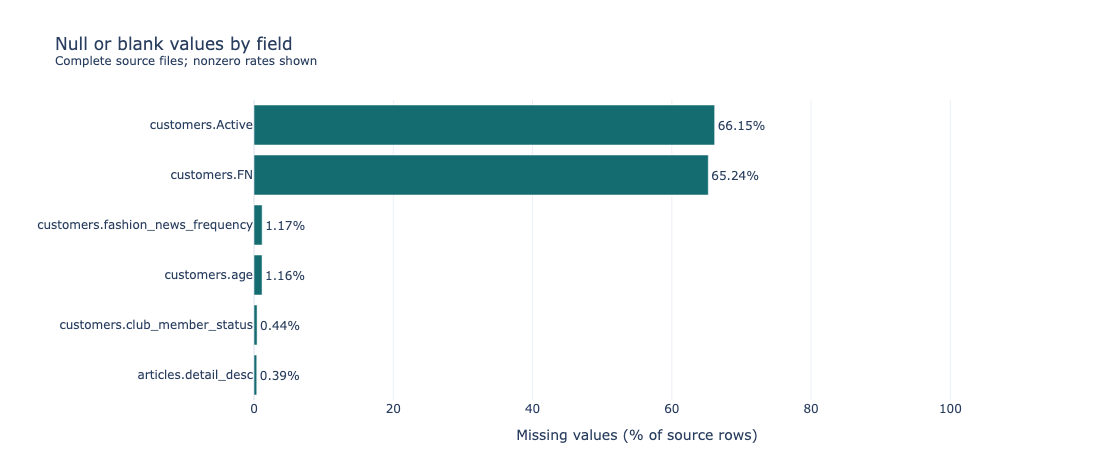

In [24]:
plot_data = (
    completeness_summary.loc[
        completeness_summary["missing_rows"].gt(0)
    ]
    .sort_values(
        ["missing_pct", "dataset", "column"],
        ascending=[False, True, True],
    )
    .copy()
)

plot_data["field"] = (
    plot_data["dataset"] + "." + plot_data["column"]
)

if plot_data.empty:
    print("No null or blank values detected under the current policy.")

else:
    fig = px.bar(
        plot_data,
        x="missing_pct",
        y="field",
        orientation="h",
        text="missing_pct",
        custom_data=["missing_rows", "rows_examined"],
        color_discrete_sequence=["#146C70"],
        template="plotly_white",
        labels={
            "missing_pct": "Missing values (% of source rows)",
            "field": "",
        },
        title=(
            "Null or blank values by field"
            "<br><sup>Complete source files; nonzero rates shown</sup>"
        ),
    )

    fig.update_traces(
        texttemplate="%{x:.2f}%",
        textposition="outside",
        cliponaxis=False,
        hovertemplate=(
            "<b>%{y}</b><br>"
            "Missing rows: %{customdata[0]:,.0f}<br>"
            "Rows examined: %{customdata[1]:,.0f}<br>"
            "Missing rate: %{x:.3f}%"
            "<extra></extra>"
        ),
    )

    fig.update_xaxes(
        range=[0, 110],
        tickvals=list(range(0, 101, 20)),
        ticksuffix="%",
    )

    fig.update_yaxes(
        categoryorder="array",
        categoryarray=plot_data["field"].tolist(),
        autorange="reversed",
        automargin=True,
    )

    fig.update_layout(
        width=1100,
        height=max(420, 50 * len(plot_data) + 170),
        margin=dict(l=40, r=80, t=100, b=70),
        showlegend=False,
    )

    fig.show(
        renderer="plotly_mimetype+png",
        config={"displaylogo": False},
    )

In [25]:
from collections import Counter

### 5.8. Customer Category Profiling Policy

Four customer attributes are profiled across the complete customer file:
FN, Active, club_member_status and fashion_news_frequency.

Counts preserve exact source values, including case and whitespace.
Each percentage uses the complete customer row count as its denominator.

Null, empty and whitespace-only values follow the existing missingness
policy. Selected nonempty textual values are flagged as potential
placeholder categories for semantic review.

A placeholder flag is a diagnostic signal, not an invalidity decision.
No categories are merged, replaced or assigned a business meaning.

In [26]:
CUSTOMER_CATEGORY_COLUMNS = (
    "FN",
    "Active",
    "club_member_status",
    "fashion_news_frequency",
)

PLACEHOLDER_CANDIDATES = frozenset({
    "unknown",
    "none",
    "nan",
    "n/a",
    "na",
    "null",
    "not available",
    "not specified",
})

In [27]:
category_counts = {
    column: Counter()
    for column in CUSTOMER_CATEGORY_COLUMNS
}

customer_rows_profiled = 0

with pd.read_csv(
    RAW_DATA_DIRECTORY / "customers.csv",
    usecols=list(CUSTOMER_CATEGORY_COLUMNS),
    chunksize=CHUNK_ROWS,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8",
) as reader:
    for chunk in reader:
        customer_rows_profiled += len(chunk)

        for column in CUSTOMER_CATEGORY_COLUMNS:
            chunk_counts = (
                chunk[column]
                .value_counts(dropna=False)
                .to_dict()
            )

            category_counts[column].update(chunk_counts)

        del chunk

if customer_rows_profiled == 0:
    raise ValueError("No customer records were inspected.")

for column, counts in category_counts.items():
    if sum(counts.values()) != customer_rows_profiled:
        raise ValueError(
            f"Category counts do not reconcile for {column}."
        )

print(f"Customer records profiled: {customer_rows_profiled:,}")

Customer records profiled: 1,371,980


In [28]:
category_profile_rows = []

for column, counts in category_counts.items():
    for raw_value, rows in counts.items():
        is_missing = (
            pd.isna(raw_value)
            or raw_value.strip() == ""
        )

        is_placeholder_candidate = (
            not is_missing
            and raw_value.strip().casefold()
            in PLACEHOLDER_CANDIDATES
        )

        category_profile_rows.append({
            "column": column,
            "raw_value": raw_value,
            "value_display": repr(raw_value),
            "rows": rows,
            "pct_rows": 100 * rows / customer_rows_profiled,
            "is_missing": is_missing,
            "placeholder_candidate": is_placeholder_candidate,
        })

category_profile = (
    pd.DataFrame(category_profile_rows)
    .sort_values(
        ["column", "rows", "value_display"],
        ascending=[True, False, True],
    )
    .reset_index(drop=True)
)

### 5.9. Customer Category Frequencies

The table reports exact source categories and their frequencies.

Quoted values make empty strings and surrounding whitespace visible.
Missingness and potential textual placeholders are reported separately.

Displayed percentages are rounded. Row counts remain available to
identify rare categories whose rounded percentage approaches zero.

In [29]:
category_profile.drop(
    columns="raw_value"
).round({
    "pct_rows": 3,
})

,column,value_display,rows,pct_rows,is_missing,placeholder_candidate
0,Active,'',907576,66.151,True,False
1,Active,'1.0',464404,33.849,False,False
2,FN,'',895050,65.238,True,False
3,FN,'1.0',476930,34.762,False,False
4,club_member_status,'ACTIVE',1272491,92.749,False,False
5,club_member_status,'PRE-CREATE',92960,6.776,False,False
6,club_member_status,'',6062,0.442,True,False
7,club_member_status,'LEFT CLUB',467,0.034,False,False
8,fashion_news_frequency,'NONE',877711,63.974,False,True
9,fashion_news_frequency,'Regularly',477416,34.798,False,False


The complete customer profile contains only blanks and '1.0' for FN
and Active. Blank values remain unresolved and are not recoded as zero.

fashion_news_frequency contains 'NONE' in 877,711 records and 'None'
in 2 records. Both source categories are retained separately pending
semantic clarification.

### 5.10. Entity-Identifier Format Policy

Entity identifiers are checked against source-format expectations:

- article_id: exactly 10 ASCII digits;
- customer_id: exactly 64 lowercase hexadecimal characters.

These expectations describe the acquired dataset version rather than
a universal identifier standard.

Checks use complete entity-key columns retained earlier in the notebook.
Missing identifiers are excluded from format matching and remain covered
by the existing completeness checks.

Matching uses exact source values. No trimming, case conversion,
numerical conversion or identifier repair is applied.

Format mismatches are reported for investigation. Matching a pattern
does not establish identifier uniqueness or referential integrity.

In [30]:
IDENTIFIER_FORMAT_PATTERNS = {
    "article_id": r"[0-9]{10}",
    "customer_id": r"[0-9a-f]{64}",
}

In [31]:
identifier_format_rows = []

for dataset_name, key_column in ENTITY_KEY_COLUMNS.items():
    values = entity_key_frames[dataset_name][key_column]

    missing_mask = values.fillna("").str.strip().eq("")
    nonmissing_values = values.loc[~missing_mask]

    lengths = nonmissing_values.str.len()

    matches = nonmissing_values.str.fullmatch(
        IDENTIFIER_FORMAT_PATTERNS[key_column],
        na=False,
    )

    identifier_format_rows.append({
        "dataset": dataset_name,
        "key_column": key_column,
        "nonmissing_rows": len(nonmissing_values),
        "min_length": lengths.min(),
        "max_length": lengths.max(),
        "format_mismatch_rows": int((~matches).sum()),
    })

identifier_format_summary = pd.DataFrame(
    identifier_format_rows
)

### 5.11. Entity-Identifier Format Results

The table reports the number of nonmissing identifiers inspected,
their observed minimum and maximum lengths, and the number of exact
source values that do not match the configured pattern.

Results cover complete entity-key columns rather than preview samples.

In [32]:
identifier_format_summary

,dataset,key_column,nonmissing_rows,min_length,max_length,format_mismatch_rows
0,articles,article_id,105542,10,10,0
1,customers,customer_id,1371980,64,64,0


### 5.12. Article Category Profiling Policy

Eleven article-classification label columns are profiled across the
complete article file.

Exact source categories are preserved. Diagnostics cover:
- distinct nonmissing source values;
- null, empty or whitespace-only values;
- candidate textual placeholders;
- leading or trailing whitespace.

Candidate placeholders reuse the customer-profiling configuration.
They are reported for semantic review rather than automatically
classified as invalid or converted to missing values.

Percentages use the complete article row count as their denominator.
They describe catalogue records, not transaction frequency.

Code-to-label consistency is assessed separately.

In [33]:
ARTICLE_CATEGORY_COLUMNS = (
    "product_type_name",
    "product_group_name",
    "graphical_appearance_name",
    "colour_group_name",
    "perceived_colour_value_name",
    "perceived_colour_master_name",
    "department_name",
    "index_name",
    "index_group_name",
    "section_name",
    "garment_group_name",
)

In [34]:
article_category_counts = {
    column: Counter()
    for column in ARTICLE_CATEGORY_COLUMNS
}

article_rows_profiled = 0

with pd.read_csv(
    RAW_DATA_DIRECTORY / "articles.csv",
    usecols=list(ARTICLE_CATEGORY_COLUMNS),
    chunksize=CHUNK_ROWS,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8",
) as reader:
    for chunk in reader:
        article_rows_profiled += len(chunk)

        for column in ARTICLE_CATEGORY_COLUMNS:
            article_category_counts[column].update(
                chunk[column]
                .value_counts(dropna=False)
                .to_dict()
            )

        del chunk

if article_rows_profiled == 0:
    raise ValueError("No article records were inspected.")

for column, counts in article_category_counts.items():
    if sum(counts.values()) != article_rows_profiled:
        raise ValueError(
            f"Category counts do not reconcile for {column}."
        )

print(f"Article records profiled: {article_rows_profiled:,}")

Article records profiled: 105,542


In [35]:
article_category_rows = []

for column, counts in article_category_counts.items():
    for raw_value, rows in counts.items():
        is_missing = (
            pd.isna(raw_value)
            or raw_value.strip() == ""
        )

        is_placeholder_candidate = (
            not is_missing
            and raw_value.strip().casefold()
            in PLACEHOLDER_CANDIDATES
        )

        has_surrounding_whitespace = (
            False
            if pd.isna(raw_value)
            else raw_value != raw_value.strip()
        )

        article_category_rows.append({
            "column": column,
            "raw_value": raw_value,
            "value_display": repr(raw_value),
            "article_rows": rows,
            "pct_articles": 100 * rows / article_rows_profiled,
            "is_missing": is_missing,
            "placeholder_candidate": is_placeholder_candidate,
            "surrounding_whitespace": has_surrounding_whitespace,
        })

article_category_profile = (
    pd.DataFrame(article_category_rows)
    .sort_values(
        ["column", "article_rows", "value_display"],
        ascending=[True, False, True],
    )
    .reset_index(drop=True)
)

In [36]:
article_category_summary_rows = []

for column in ARTICLE_CATEGORY_COLUMNS:
    column_profile = article_category_profile.loc[
        article_category_profile["column"].eq(column)
    ]

    missing_rows = int(
        column_profile.loc[
            column_profile["is_missing"], "article_rows"
        ].sum()
    )

    placeholder_rows = int(
        column_profile.loc[
            column_profile["placeholder_candidate"], "article_rows"
        ].sum()
    )

    whitespace_rows = int(
        column_profile.loc[
            column_profile["surrounding_whitespace"], "article_rows"
        ].sum()
    )

    article_category_summary_rows.append({
        "column": column,
        "distinct_nonmissing_values": int(
            (~column_profile["is_missing"]).sum()
        ),
        "missing_rows": missing_rows,
        "placeholder_rows": placeholder_rows,
        "placeholder_pct": (
            100 * placeholder_rows / article_rows_profiled
        ),
        "whitespace_rows": whitespace_rows,
    })

article_category_summary = pd.DataFrame(
    article_category_summary_rows
)

### 5.13. Article Category Diagnostics

The summary distinguishes category cardinality from the number of
article records affected by each diagnostic.

Distinct-value counts preserve source spelling and include nonempty
placeholder categories. Diagnostic counts can overlap.

The focused table below retains exact source values requiring review.
Neither table establishes category validity or purchase popularity.

In [37]:
article_category_summary.round({
    "placeholder_pct": 3,
})

,column,distinct_nonmissing_values,missing_rows,placeholder_rows,placeholder_pct,whitespace_rows
0,product_type_name,131,0,121,0.115,0
1,product_group_name,19,0,121,0.115,0
2,graphical_appearance_name,30,0,52,0.049,0
3,colour_group_name,50,0,28,0.027,0
4,perceived_colour_value_name,8,0,28,0.027,0
5,perceived_colour_master_name,20,0,685,0.649,0
6,department_name,250,0,0,0.000,0
7,index_name,10,0,0,0.000,0
8,index_group_name,5,0,0,0.000,0
9,section_name,56,0,0,0.000,0


In [38]:
article_category_profile.loc[
    article_category_profile["placeholder_candidate"]
    | article_category_profile["surrounding_whitespace"],
    [
        "column",
        "value_display",
        "article_rows",
        "pct_articles",
        "surrounding_whitespace",
    ],
].round({
    "pct_articles": 3,
})

,column,value_display,article_rows,pct_articles,surrounding_whitespace
48,colour_group_name,'Unknown',28,0.027,False
310,garment_group_name,'Unknown',3873,3.670,False
348,graphical_appearance_name,'Unknown',52,0.049,False
382,perceived_colour_master_name,'Unknown',685,0.649,False
393,perceived_colour_value_name,'Unknown',28,0.027,False
403,product_group_name,'Unknown',121,0.115,False
477,product_type_name,'Unknown',121,0.115,False


### 5.14. Numerical Diagnostic Policy

Numerical diagnostics distinguish source missingness, parsing failures,
nonfinite values, negative values and zeros.

Parsing failures are reported using a diagnostic numeric copy.
Source strings and files remain unchanged.

Flags can overlap and are not automatically interpreted as removal rules.
Percentages use all rows in the corresponding source table.

Age-specific checks additionally identify fractional values and values
above an explicit review threshold. The threshold is a review trigger,
not a validated business constraint.

In [39]:
def numeric_diagnostics(raw_values):
    missing = raw_values.fillna("").str.strip().eq("")

    numeric = pd.to_numeric(
        raw_values.mask(missing),
        errors="coerce",
    ).astype("Float64")

    finite = (
        numeric.notna()
        & ~numeric.isin([float("inf"), float("-inf")])
    )

    counts = {
        "missing": int(missing.sum()),
        "unparseable": int(
            (~missing & numeric.isna()).sum()
        ),
        "nonfinite": int(
            (numeric.notna() & ~finite).sum()
        ),
        "negative": int(
            (finite & numeric.lt(0)).sum()
        ),
        "zero": int(
            (finite & numeric.eq(0)).sum()
        ),
    }

    return numeric, finite, counts


def quality_table(counts, total_rows):
    if total_rows <= 0:
        raise ValueError(
            "Quality rates require a positive source row count."
        )

    return pd.DataFrame([
        {
            "check": name,
            "affected_rows": count,
            "pct_source_rows": 100 * count / total_rows,
        }
        for name, count in counts.items()
    ])

### 5.15. Customer Age Diagnostics

The complete source age column is inspected independently of the
unresolved observation date of customer metadata.

Negative, fractional, zero and unusually high values are reported.
The review threshold is set to 100 years and does not trigger filtering.

Descriptive statistics and the chart cover finite numeric ages only.
Successful diagnostics do not establish historical feature availability.

In [40]:
AGE_REVIEW_THRESHOLD = 100

age_raw = pd.read_csv(
    RAW_DATA_DIRECTORY / "customers.csv",
    usecols=["age"],
    dtype="string",
    keep_default_na=False,
    encoding="utf-8",
)["age"]

age_numeric, age_finite, age_counts = numeric_diagnostics(
    age_raw
)

age_counts["fractional"] = int(
    (age_finite & age_numeric.mod(1).ne(0)).sum()
)

age_counts["above_review_threshold"] = int(
    (
        age_finite
        & age_numeric.gt(AGE_REVIEW_THRESHOLD)
    ).sum()
)

age_diagnostics = quality_table(
    age_counts,
    total_rows=len(age_raw),
)

age_diagnostics.round({"pct_source_rows": 4})

,check,affected_rows,pct_source_rows
0,missing,15861,1.1561
1,unparseable,0,0.0000
2,nonfinite,0,0.0000
3,negative,0,0.0000
4,zero,0,0.0000
5,fractional,0,0.0000
6,above_review_threshold,0,0.0000


In [41]:
age_numeric.loc[age_finite].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
)

count    1356119.0
mean     36.386965
std      14.313628
min           16.0
1%            18.0
25%           24.0
50%           32.0
75%           49.0
99%           71.0
max           99.0
Name: age, dtype: Float64

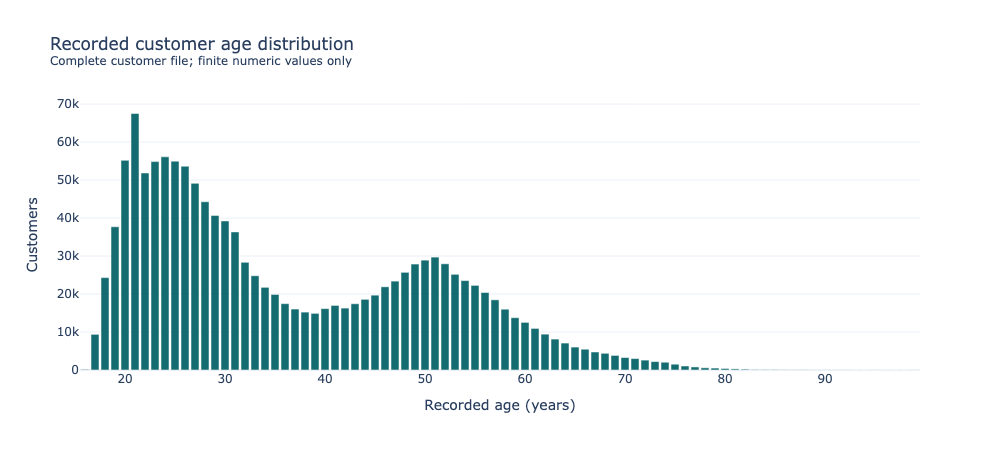

In [42]:
age_distribution = (
    age_numeric.loc[age_finite]
    .value_counts()
    .sort_index()
    .rename_axis("age")
    .reset_index(name="customers")
)

fig = px.bar(
    age_distribution,
    x="age",
    y="customers",
    color_discrete_sequence=["#146C70"],
    template="plotly_white",
    labels={
        "age": "Recorded age (years)",
        "customers": "Customers",
    },
    title=(
        "Recorded customer age distribution"
        "<br><sup>Complete customer file; "
        "finite numeric values only</sup>"
    ),
)

fig.update_layout(
    width=1000,
    height=450,
    showlegend=False,
)

fig.update_yaxes(rangemode="tozero")

fig.show(
    renderer="plotly_mimetype+png",
    config={"displaylogo": False},
)

### 5.16. Transaction Validity and Repetition Scan

Transactions are inspected in chunks without changing source values.

Date diagnostics check the exact YYYY-MM-DD representation and calendar
parsing. Price diagnostics follow the numerical policy above.

Sales-channel codes are profiled as source strings. No business labels
are assigned.

Exact transaction patterns are defined by equal values across all five
acquired source columns. Repetition counts are accumulated across chunk
boundaries using a persistent counter for the current date.

This strategy requires complete valid ISO dates in nondecreasing order.
The scan stops if these prerequisites are not met.

After a date is complete, only the distribution of pattern multiplicities
is retained. Memory therefore depends on the current chunk and day,
rather than the full transaction history.

No transaction records are removed.

In [43]:
TRANSACTION_COLUMNS = (
    "t_dat",
    "customer_id",
    "article_id",
    "price",
    "sales_channel_id",
)

transaction_checks = Counter()
channel_counts = Counter()

transaction_rows_profiled = 0
finite_price_rows = 0
price_min = None
price_max = None

current_date = None
current_day_counts = Counter()
multiplicity_counts = Counter()

In [44]:
with pd.read_csv(
    RAW_DATA_DIRECTORY / "transactions_train.csv",
    usecols=list(TRANSACTION_COLUMNS),
    chunksize=CHUNK_ROWS,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8",
) as reader:
    for chunk_number, chunk in enumerate(reader, start=1):
        transaction_rows_profiled += len(chunk)

        # Date validity.
        dates = chunk["t_dat"]
        date_missing = dates.fillna("").str.strip().eq("")

        date_format = dates.str.fullmatch(
            r"[0-9]{4}-[0-9]{2}-[0-9]{2}",
            na=False,
        )

        parsed_dates = pd.to_datetime(
            dates.mask(date_missing),
            format="%Y-%m-%d",
            errors="coerce",
        )

        transaction_checks.update({
            "date_missing": int(date_missing.sum()),
            "date_format_mismatch": int(
                (~date_missing & ~date_format).sum()
            ),
            "date_unparseable": int(
                (~date_missing & parsed_dates.isna()).sum()
            ),
        })

        if (
            date_missing.any()
            or (~date_format).any()
            or parsed_dates.isna().any()
        ):
            raise ValueError(
                "Repetition scanning requires complete valid ISO dates. "
                "Inspect transaction_checks before continuing."
            )

        if (
            not dates.is_monotonic_increasing
            or (
                current_date is not None
                and dates.iloc[0] < current_date
            )
        ):
            raise ValueError(
                "Transactions are not ordered by date. "
                "The chronological repetition scan cannot continue."
            )

        # Price validity and finite range.
        prices, price_finite, price_counts = (
            numeric_diagnostics(chunk["price"])
        )

        transaction_checks.update({
            f"price_{name}": count
            for name, count in price_counts.items()
        })

        finite_price_rows += int(price_finite.sum())

        if price_finite.any():
            chunk_min = float(prices.loc[price_finite].min())
            chunk_max = float(prices.loc[price_finite].max())

            price_min = (
                chunk_min
                if price_min is None
                else min(price_min, chunk_min)
            )

            price_max = (
                chunk_max
                if price_max is None
                else max(price_max, chunk_max)
            )

        # Source sales-channel codes.
        channels = chunk["sales_channel_id"]
        channel_missing = (
            channels.fillna("").str.strip().eq("")
        )

        transaction_checks.update({
            "channel_missing": int(channel_missing.sum()),
            "channel_format_mismatch": int(
                (
                    ~channel_missing
                    & ~channels.str.fullmatch(
                        r"[0-9]+",
                        na=False,
                    )
                ).sum()
            ),
        })

        channel_counts.update(
            channels.value_counts(dropna=False).to_dict()
        )

        # Exact patterns, retaining state across chunks.
        for day, day_rows in chunk.groupby("t_dat", sort=False):
            if day != current_date:
                multiplicity_counts.update(
                    current_day_counts.values()
                )
                current_day_counts.clear()
                current_date = day

            current_day_counts.update(
                day_rows.value_counts(
                    sort=False,
                    dropna=False,
                ).to_dict()
            )

        if chunk_number % 50 == 0:
            print(
                f"{transaction_rows_profiled:,} "
                "transaction rows inspected",
                flush=True,
            )

        del chunk

if transaction_rows_profiled == 0:
    raise ValueError("No transaction records were inspected.")

# Flush the final day, which has no following date to trigger closure.
multiplicity_counts.update(current_day_counts.values())
current_day_counts.clear()

reconciled_rows = sum(
    multiplicity * groups
    for multiplicity, groups in multiplicity_counts.items()
)

if reconciled_rows != transaction_rows_profiled:
    raise ValueError("Repetition counts do not reconcile.")

if sum(channel_counts.values()) != transaction_rows_profiled:
    raise ValueError("Channel counts do not reconcile.")

print(
    f"Completed: {transaction_rows_profiled:,} transaction rows."
)

5,000,000 transaction rows inspected
10,000,000 transaction rows inspected
15,000,000 transaction rows inspected
20,000,000 transaction rows inspected
25,000,000 transaction rows inspected
30,000,000 transaction rows inspected
Completed: 31,788,324 transaction rows.


### 5.17. Transaction Validity Results

Diagnostic rates use the complete transaction row count.
Price extrema use finite numeric values and retain source units.

Channel frequencies describe transaction rows, not distinct customers.
Observed codes are not assigned an unverified store/online mapping.

These checks establish representation and numerical properties.
Temporal coverage and evaluation boundaries are assessed separately.

In [45]:
transaction_diagnostics = quality_table(
    transaction_checks,
    total_rows=transaction_rows_profiled,
)

transaction_diagnostics.round({
    "pct_source_rows": 4,
})

,check,affected_rows,pct_source_rows
0,date_missing,0,0.0
1,date_format_mismatch,0,0.0
2,date_unparseable,0,0.0
3,price_missing,0,0.0
4,price_unparseable,0,0.0
5,price_nonfinite,0,0.0
6,price_negative,0,0.0
7,price_zero,0,0.0
8,channel_missing,0,0.0
9,channel_format_mismatch,0,0.0


In [46]:
price_range_summary = pd.DataFrame([{
    "finite_price_rows": finite_price_rows,
    "minimum_source_price": price_min,
    "maximum_source_price": price_max,
}])

price_range_summary

,finite_price_rows,minimum_source_price,maximum_source_price
0,31788324,0.000017,0.591525


In [47]:
channel_summary = pd.DataFrame([
    {
        "source_value": repr(value),
        "transaction_rows": rows,
        "pct_source_rows": (
            100 * rows / transaction_rows_profiled
        ),
    }
    for value, rows in channel_counts.items()
]).sort_values("source_value").reset_index(drop=True)

channel_summary.round({
    "pct_source_rows": 3,
})

,source_value,transaction_rows,pct_source_rows
0,'1',9408462,29.597
1,'2',22379862,70.403


### 5.18. Exact Transaction Repetitions

An exact pattern consists of equal source values across all five
transaction columns.

Three quantities are distinguished:
- repeated patterns;
- all rows belonging to repeated patterns;
- additional occurrences beyond the first occurrence of each pattern.

The source documentation describes repeated rows as multiple purchases
of the same item. Transactions are therefore retained.

A repeated pattern does not identify an order, basket or ingestion error.

For ranking evaluation, repeated purchases will contribute one distinct
relevant article per customer and target window, as defined in the
evaluation strategy.

Source: [H&M dataset documentation](
https://www.kaggle.com/competitions/h-and-m-personalized-fashion-recommendations/data
).

In [48]:
distinct_patterns = sum(multiplicity_counts.values())

repeated_patterns = sum(
    groups
    for multiplicity, groups in multiplicity_counts.items()
    if multiplicity > 1
)

rows_in_repeated_patterns = sum(
    multiplicity * groups
    for multiplicity, groups in multiplicity_counts.items()
    if multiplicity > 1
)

additional_repeated_rows = sum(
    (multiplicity - 1) * groups
    for multiplicity, groups in multiplicity_counts.items()
)

repetition_summary = pd.DataFrame([
    {
        "metric": "source_transaction_rows",
        "value": transaction_rows_profiled,
    },
    {
        "metric": "distinct_exact_patterns",
        "value": distinct_patterns,
    },
    {
        "metric": "repeated_patterns",
        "value": repeated_patterns,
    },
    {
        "metric": "rows_in_repeated_patterns",
        "value": rows_in_repeated_patterns,
    },
    {
        "metric": "additional_repeated_rows",
        "value": additional_repeated_rows,
    },
    {
        "metric": "maximum_pattern_multiplicity",
        "value": max(multiplicity_counts),
    },
])

repetition_summary

,metric,value
0,source_transaction_rows,31788324
1,distinct_exact_patterns,28813419
2,repeated_patterns,2543908
3,rows_in_repeated_patterns,5518813
4,additional_repeated_rows,2974905
5,maximum_pattern_multiplicity,569


In [49]:
repetition_rates = quality_table(
    {
        "rows_in_repeated_patterns": rows_in_repeated_patterns,
        "additional_repeated_rows": additional_repeated_rows,
    },
    total_rows=transaction_rows_profiled,
)

repetition_rates.round({
    "pct_source_rows": 3,
})

,check,affected_rows,pct_source_rows
0,rows_in_repeated_patterns,5518813,17.361
1,additional_repeated_rows,2974905,9.358


### 5.19. Article Code-to-Label Consistency

Ten classification code/label pairs are inspected using exact source
values.

A code associated with multiple labels is reported as a mapping
conflict requiring investigation.

A label associated with multiple codes is reported separately.
Labels are not assumed to be unique identifiers.

Distinct code/label links are used only for diagnostics.
No article records or source classifications are modified.

In [50]:
ARTICLE_CODE_LABEL_PAIRS = {
    "product_type_no": "product_type_name",
    "graphical_appearance_no": "graphical_appearance_name",
    "colour_group_code": "colour_group_name",
    "perceived_colour_value_id": "perceived_colour_value_name",
    "perceived_colour_master_id": "perceived_colour_master_name",
    "department_no": "department_name",
    "index_code": "index_name",
    "index_group_no": "index_group_name",
    "section_no": "section_name",
    "garment_group_no": "garment_group_name",
}

articles_quality = pd.read_csv(
    RAW_DATA_DIRECTORY / "articles.csv",
    dtype="string",
    keep_default_na=False,
    encoding="utf-8",
)

In [55]:
code_label_rows = []
shared_label_rows = []

for code_column, label_column in ARTICLE_CODE_LABEL_PAIRS.items():
    missing_pair = (
        articles_quality[code_column].str.strip().eq("")
        | articles_quality[label_column].str.strip().eq("")
    )

    links = (
        articles_quality.loc[
            ~missing_pair,
            [code_column, label_column],
        ]
        .drop_duplicates()
    )

    labels_per_code = (
        links.groupby(code_column)[label_column].nunique()
    )

    codes_per_label = (
        links.groupby(label_column)[code_column].nunique()
    )

    conflicting_codes = labels_per_code.index[
        labels_per_code.gt(1)
    ]

    shared_labels = codes_per_label.index[
        codes_per_label.gt(1)
    ]

    code_label_rows.append({
        "code_column": code_column,
        "label_column": label_column,
        "missing_pair_rows": int(missing_pair.sum()),
        "codes_with_multiple_labels": len(conflicting_codes),
        "affected_article_rows": int(
            articles_quality[code_column]
            .isin(conflicting_codes)
            .sum()
        ),
        "labels_with_multiple_codes": len(shared_labels),
    })

    for _, link in links.loc[
        links[label_column].isin(shared_labels)
    ].iterrows():
        shared_label_rows.append({
            "code_column": code_column,
            "label": link[label_column],
            "code": link[code_column],
        })

code_label_summary = pd.DataFrame(code_label_rows)

shared_label_details = pd.DataFrame(
    shared_label_rows,
    columns=["code_column", "label", "code"],
)

In [56]:
code_label_summary

,code_column,label_column,missing_pair_rows,codes_with_multiple_labels,affected_article_rows,labels_with_multiple_codes
0,product_type_no,product_type_name,0,0,0,1
1,graphical_appearance_no,graphical_appearance_name,0,0,0,0
2,colour_group_code,colour_group_name,0,0,0,0
3,perceived_colour_value_id,perceived_colour_value_name,0,0,0,0
4,perceived_colour_master_id,perceived_colour_master_name,0,0,0,0
5,department_no,department_name,0,0,0,22
6,index_code,index_name,0,0,0,0
7,index_group_no,index_group_name,0,0,0,0
8,section_no,section_name,0,0,0,1
9,garment_group_no,garment_group_name,0,0,0,0


In [57]:
shared_label_details.groupby(
    "code_column",
    sort=False,
).head(4)

,code_column,label,code
0,product_type_no,Umbrella,532
1,product_type_no,Umbrella,83
2,department_no,Jersey Basic,1676
3,department_no,Jersey Basic,5883
4,department_no,Jersey,2032
5,department_no,EQ & Special Collections,4342
73,section_no,Ladies Other,4
74,section_no,Ladies Other,17


### 5.20. Article and Product Grouping

The complete article catalogue is used to measure the relationship
between article_id and product_code.

article_id remains the recommendation and transaction identifier.
product_code is retained as a grouping identifier.

Multiple articles sharing a product code are not treated as duplicate
article records. No unsupported size or variant interpretation is
assigned to the identifier structure.

In [58]:
products_per_article = (
    articles_quality
    .groupby("article_id")["product_code"]
    .nunique()
)

articles_per_product = (
    articles_quality
    .groupby("product_code")["article_id"]
    .nunique()
)

product_grouping_summary = pd.DataFrame([{
    "article_rows": len(articles_quality),
    "distinct_articles": articles_quality["article_id"].nunique(),
    "distinct_product_codes": articles_quality["product_code"].nunique(),
    "articles_with_multiple_product_codes": int(
        products_per_article.gt(1).sum()
    ),
    "product_codes_with_multiple_articles": int(
        articles_per_product.gt(1).sum()
    ),
    "maximum_articles_per_product_code": int(
        articles_per_product.max()
    ),
}])

product_grouping_summary

,article_rows,distinct_articles,distinct_product_codes,articles_with_multiple_product_codes,product_codes_with_multiple_articles,maximum_articles_per_product_code
0,105542,105542,47224,0,23158,75


### 5.21. Data-Quality Decisions

The completed checks support the following handling decisions.

| Area | Evidence | Decision |
|---|---|---|
| Entity keys | Complete, unique and consistent with configured source-format expectations | Preserve exact string identifiers |
| Transaction references | All article and customer references match their entity tables | Retain the validated many-to-one join design |
| Customer age | 15,861 missing values; finite recorded ages range from 16 to 99 | Preserve missingness; defer imputation and feature eligibility |
| FN and Active | Source values consist of blanks and '1.0'; business semantics remain unresolved | Do not recode blanks as zero; exclude from initial model inputs |
| Customer categories | 'NONE' and 'None' occur separately | Preserve raw categories pending semantic clarification |
| Article categories | Nonempty 'Unknown' categories occur despite zero blank classification labels | Retain and document these categories; do not silently treat them as known attributes |
| Transaction dates | Complete, parseable ISO dates; nondecreasing source order verified | Proceed to temporal-coverage analysis |
| Transaction prices | Complete, finite and strictly positive under the defined diagnostics | Preserve source units and scaling |
| Sales channels | Codes '1' and '2' observed | Preserve codes without assigning an unsupported business mapping |
| Repeated transactions | 2,974,905 additional exact-pattern occurrences | Retain source records, following dataset documentation |
| Ranking relevance | Repeated purchases can concern the same article | Use distinct relevant articles per customer and target window |
| Classification mappings | Each inspected code has one label; some labels have multiple codes | Preserve codes and labels; do not assume label uniqueness |
| Product grouping | 105,542 articles share 47,224 product codes | Recommend article_id; retain product_code for grouping |

These checks do not establish metadata availability at historical
prediction dates, price units, business impact or overall model quality.

Temporal coverage, evaluation boundaries and stable reusable validation
functions remain subsequent work.